# Modelos ML | Modelo #4 - Random Forest

Este notebook estima a superfície de volatilidade implícita (IVS) usando 

Autor: Sérgio Sobral  
Data: 11/09/2025

Importação de Bibliotecas

In [1]:
import os
import json
import joblib
from datetime import datetime, timezone
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, SplineTransformer
from sklearn.linear_model import RidgeCV
from sklearn.linear_model import LinearRegression
from typing import Optional, Sequence, Iterable, Tuple
from sklearn.base import BaseEstimator, TransformerMixin

from __future__ import annotations

from sklearn.ensemble import RandomForestRegressor

Designações Centrais e Caminhos

In [2]:
# Designações Centrais e Caminhos
DIR_TRATADOS = "02. Dados/02. Dados Tratados/"
DIR_RESULTADOS = "04. Resultados/04. Modelo #4 - Random Forest/"
DIR_GRAFICOS = "03. Output/01. Gráficos/07. Modelo #4 - Random Forest/"
DIR_TABELAS = "03. Output/02. Tabelas/04. Modelo #4 - Random Forest/"

# Criar diretório de gráficos/tabelas/resultados se não existir
os.makedirs(DIR_GRAFICOS, exist_ok=True)
os.makedirs(DIR_RESULTADOS, exist_ok=True)
os.makedirs(DIR_TABELAS, exist_ok=True)

# Ficheiros de input
ficheiro_universo        = os.path.join(DIR_TRATADOS, "Universo_Modelizacao_v1.00.parquet")
ficheiro_inner_train     = os.path.join(DIR_TRATADOS, "df_inner_train.parquet")
ficheiro_inner_tunning   = os.path.join(DIR_TRATADOS, "df_inner_tunning.parquet")
ficheiro_train_full      = os.path.join(DIR_TRATADOS, "df_train_full.parquet")
ficheiro_test_puro       = os.path.join(DIR_TRATADOS, "df_test_puro.parquet")

# Config
FEATURES = ("log_moneyness", "T", "risk_free_rate", "option_is_call")
TARGET   = "iv_teorica"
PRED_COL = "ivs_modelo"


# Save Models (nomes finais)
MODEL_PATH_INNER = os.path.join(DIR_RESULTADOS, "04. RF_model_inner.joblib")
META_PATH_INNER  = os.path.join(DIR_RESULTADOS, "04. RF_model_inner.meta.json")

BEST_PARAMS = os.path.join(DIR_RESULTADOS, "04. RF_best_params.json")
LINEAR_ADJUST = os.path.join(DIR_RESULTADOS, "04. RF_linear_adjust.json")

MODEL_PATH_FINAL = os.path.join(DIR_RESULTADOS, "04. RF_model.joblib")
META_PATH_FINAL  = os.path.join(DIR_RESULTADOS, "04. RF_model.meta.json")

Funções Auxiliares

Palete de Cores:
azul1: #11469b
azul2: #2063c0
azul3: #5a90e7
cinza1: #777777
cinza2: #AAAAAA
cinza3: #bbbbbb
preto: #000000
branco: #ffffff

Estilos de Linha:
contínua: -
tracejada: --
ponto-traço: -.
pontilhada: :
contínua2: -
tracejada2: --
ponto-traço2: -.
pontilhada2: :


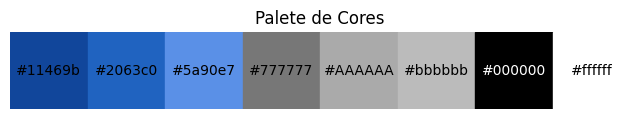

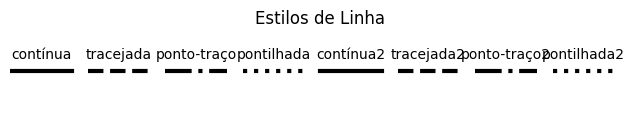

In [3]:
%run "01. Notebooks/00. Configuração/02_Ficheiro Auxiliar.ipynb"

# Visualizar paleta de cores e estilos de linha carregados
if 'mostrar_cores' in globals() and 'PALETA_CORES' in globals():
    mostrar_cores(PALETA_CORES)
if 'mostrar_estilos' in globals() and 'ESTILOS_LINHA' in globals():
    mostrar_estilos(ESTILOS_LINHA)

Carregamento dos Dados

In [4]:
# Carregamento do ficheiro parquet
df_inner_train = pd.read_parquet(ficheiro_inner_train)
df_inner_tunning = pd.read_parquet(ficheiro_inner_tunning)
df_train_full = pd.read_parquet(ficheiro_train_full)
df_test_puro = pd.read_parquet(ficheiro_test_puro)

# Verificação inicial
(df_inner_train.shape, df_inner_tunning.shape, df_train_full.shape, df_test_puro.shape)

((5970843, 11), (1534395, 11), (7505238, 11), (1292514, 11))

Validação se option_is_call tem importância para efeitos de modelização

In [5]:
from sklearn.metrics import root_mean_squared_error
import numpy as np

FEATURES_BASE = ("log_moneyness", "T", "risk_free_rate")
FEATURES_PLUS = ("log_moneyness", "T", "risk_free_rate", "option_is_call")

def build_rf():
    return RandomForestRegressor(
        n_estimators=600, max_depth=14,
        min_samples_leaf=100, min_samples_split=300,
        max_features='sqrt', bootstrap=True, max_samples=0.8,
        random_state=42, n_jobs=-1
    )

def rmse(true, pred):
    return root_mean_squared_error(true, pred)

def fit_and_eval(train_df, val_df, cols):
    rf = build_rf()
    rf.fit(train_df[list(cols)], train_df["iv_teorica"])
    pred = rf.predict(val_df[list(cols)])
    return rmse(val_df["iv_teorica"], pred), rf

rmse_base, rf_base   = fit_and_eval(df_inner_train, df_inner_tunning, FEATURES_BASE)
rmse_plus, rf_plus   = fit_and_eval(df_inner_train, df_inner_tunning, FEATURES_PLUS)
print({"RMSE_BASE": rmse_base, "RMSE_PLUS": rmse_plus, "Delta": rmse_plus - rmse_base})


{'RMSE_BASE': 0.05510783670461701, 'RMSE_PLUS': 0.04675298866968976, 'Delta': -0.008354848034927254}


> 📌 Interpretação

🔽 O RMSE baixou em mais de 0.0083 ao incluir a variável option_is_call.

Em termos relativos, 0.00835/0.0551 ≈ 15.1%
👉 Ou seja, uma melhoria de ~15% no erro (root mean squared error) ao incluir a dummy.

✅ Conclusão: option_is_call é relevante para o teu modelo — pelo menos em inner_tunning. Provavelmente está a capturar assimetrias não modeladas apenas por log_moneyness e T, mesmo que tenhas usado preços médios (mid), e mesmo com LM centrado.
🧠 O que isto nos diz? Apesar de log_moneyness já “absorver” parte da diferença entre calls e puts, ainda há comportamentos sistemáticos diferentes que o RF está a conseguir explorar. O RF aprendeu a “ajustar” um pouco para calls vs puts em regiões equivalentes de LM e maturidade.

Modelização | Setup Inicial

In [6]:
# 1) Checks básicos
def _basic_checks(df, features, target):
    cols = list(features) + [target]
    em_falta = [c for c in cols if c not in df.columns]
    if em_falta: raise ValueError(f"Colunas em falta: {em_falta}")

    sub = df[cols]
    nan_counts = sub.isna().sum()
    if nan_counts.any():
        raise ValueError(f"Há NaN nas colunas usadas: {nan_counts[nan_counts>0].to_dict()}")

    inf_detalhe = {}
    for c in cols:
        v = sub[c].to_numpy()
        if not np.isfinite(v).all():
            inf_detalhe[c] = int(np.isinf(v).sum()) + int(np.isnan(v).sum())
    if inf_detalhe:
        raise ValueError(f"Valores não finitos detectados: {inf_detalhe}")
    return sub



# ---------------------------------------------------------------------
# 2) Utilidades de dtype e sampling (RAM‑safe)
def _prepare_xy(df: pd.DataFrame, features: Iterable[str], target: str):
    # Cast eficiente para poupar RAM
    df2 = df.copy()
    for c in features:
        if c == "option_is_call":
            df2[c] = df2[c].astype("int8")
        else:
            df2[c] = df2[c].astype("float32")

    X = df2[list(features)].values 
    y = df2[target].astype("float32")  
    return X, y

def _make_bins(df: pd.DataFrame, lm_col="log_moneyness", t_col="T", n_lm=30, n_t=12):
    lm_bins = np.linspace(df[lm_col].min(), df[lm_col].max(), n_lm+1)
    t_bins  = np.linspace(df[t_col].min(),  df[t_col].max(),  n_t+1)
    return lm_bins, t_bins

def balanced_sample(df, max_per_bin=5000, lm_col="log_moneyness", t_col="T"):
    df = df.copy()
    lm_q = np.quantile(df[lm_col].values, np.linspace(0, 1, 31))
    t_q  = np.quantile(df[t_col].values,  np.linspace(0, 1, 13))
    lm_edges = np.unique(lm_q)
    t_edges  = np.unique(t_q)
    if lm_edges.size < 3:
        lm_edges = np.linspace(df[lm_col].min(), df[lm_col].max(), 31)
    if t_edges.size < 3:
        t_edges  = np.linspace(df[t_col].min(),  df[t_col].max(),  13)

    lm_cat = pd.cut(df[lm_col], bins=lm_edges, include_lowest=True, right=False)
    t_cat  = pd.cut(df[t_col],  bins=t_edges,  include_lowest=True, right=False)
    df["_lm_bin"] = lm_cat.cat.codes
    df["_t_bin"]  = t_cat.cat.codes

    out = (df.loc[(df["_lm_bin"]>=0) & (df["_t_bin"]>=0)]
             .groupby(["_lm_bin","_t_bin"], group_keys=False)
             .apply(lambda g: g.sample(min(len(g), max_per_bin), random_state=42))
             .drop(columns=["_lm_bin","_t_bin"]))
    return out



# ---------------------------------------------------------------------
# 3) Construção do modelo

from sklearn.ensemble import RandomForestRegressor

def build_rf(params: dict | None = None) -> RandomForestRegressor:
    base = dict(
        n_estimators=600,
        max_depth=14,
        min_samples_leaf=100,
        min_samples_split=300,
        max_features='sqrt',
        bootstrap=True,
        max_samples=0.8,
        n_jobs=-1,
        random_state=42,
        oob_score=False,   # podes ativar se quiseres diagnóstico interno
    )
    if params: base.update(params)
    return RandomForestRegressor(**base)


# ---------------------------------------------------------------------
# 4) Tuning do modelo

def tune_rf(
    df_inner_train: pd.DataFrame,
    df_inner_tunning: pd.DataFrame,
    features: Iterable[str],
    target: str,
    n_iter: int = 24,
    use_balanced_sample: bool = True,
    max_per_bin: int = 5000,
    random_state: int = 42,
) -> dict:
    _basic_checks(df_inner_train, features, target)
    _basic_checks(df_inner_tunning, features, target)

    train_df = balanced_sample(df_inner_train, max_per_bin=max_per_bin) if use_balanced_sample else df_inner_train

    X_tr_s, y_tr_s = _prepare_xy(train_df, features, target)
    X_in,  y_in    = _prepare_xy(df_inner_train,   features, target)
    X_va,  y_va    = _prepare_xy(df_inner_tunning, features, target)

    rf = build_rf({"n_jobs": 1})  # evitar paralelismo aninhado
    param_dist = {
        # Run 1
        # "n_estimators":      [300, 600, 900],
        # "max_depth":         [10, 14, 18, None],
        # "min_samples_leaf":  [50, 100, 200, 300],
        # "min_samples_split": [100, 300, 500, 800],
        # "max_features":      ['sqrt', 0.5, 0.7],
        # "max_samples":       [0.6, 0.8, 0.9],
        # "bootstrap":         [True],

        # Run 2
        # "n_estimators":      [500, 600, 700],
        # "max_depth":         [12, 16],
        # "min_samples_leaf":  [50, 100],
        # "min_samples_split": [200, 300],
        # "max_features":      [0.8, 1.0],
        # "max_samples":       [0.6, 0.8],
        # "bootstrap":         [True],

        # Run 3
        "n_estimators":      [500, 600],
        "max_depth":         [14, 16],
        "min_samples_leaf":  [50, 100],
        "min_samples_split": [200, 300, 400],
        "max_features":      [0.8, 1.0],
        "max_samples":       [0.6, 0.8],
        "bootstrap":         [True],
    }

    from sklearn.model_selection import RandomizedSearchCV
    rs = RandomizedSearchCV(
        rf, param_distributions=param_dist, n_iter=n_iter,
        scoring="neg_root_mean_squared_error", cv=2, n_jobs=-1,
        random_state=random_state, verbose=1, refit=False, return_train_score=False,
        error_score="raise",
    )
    rs.fit(X_tr_s, y_tr_s)
    best_params = dict(rs.best_params_)

    # Refit no inner_train completo com os melhores parâmetros
    rf_refit = build_rf({**best_params, "n_jobs": -1})
    rf_refit.fit(X_in, y_in)

    # Previsões (clip só nas PREVISÕES)
    y_hat_in = np.clip(rf_refit.predict(X_in).astype("float32"), 1e-4, 2.0)
    y_hat_va = np.clip(rf_refit.predict(X_va).astype("float32"), 1e-4, 2.0)

    df_inner_train_pred   = df_inner_train.copy()
    df_inner_tunning_pred = df_inner_tunning.copy()
    df_inner_train_pred[PRED_COL]   = y_hat_in
    df_inner_tunning_pred[PRED_COL] = y_hat_va

    return best_params, df_inner_train_pred, df_inner_tunning_pred



# ---------------------------------------------------------------------
# 5) Treinar modelo final
from datetime import datetime, timezone

def train_rf(
    df_train_full: pd.DataFrame,
    features: Iterable[str],
    target: str,
    best_params: dict | None = None,
    oob_score: bool = False,
    return_in_sample_pred: bool = True,
    pred_col: str = PRED_COL
) -> tuple[RandomForestRegressor, dict, pd.DataFrame | None]:
    _basic_checks(df_train_full, features, target)
    X_tr, y_tr = _prepare_xy(df_train_full, features, target)

    params = dict(best_params) if best_params else {}
    if oob_score:
        params["oob_score"] = True
        params["bootstrap"] = True
        params.setdefault("max_samples", 0.8)

    rf = build_rf(params)
    rf.fit(X_tr, y_tr)

    meta = {
        "model_type": "RandomForestRegressor",
        "features": list(features),
        "target": target,
        "n_obs": int(X_tr.shape[0]),
        "params": rf.get_params(),
        "oob_score": float(getattr(rf, "oob_score_", np.nan)) if oob_score else None,
        "trained_at": datetime.now(timezone.utc).isoformat() + "Z",
        "date_min": str(df_train_full["quote_date"].min()) if "quote_date" in df_train_full.columns else None,
        "date_max": str(df_train_full["quote_date"].max()) if "quote_date" in df_train_full.columns else None,
    }

    df_train_pred = None
    if return_in_sample_pred:
        y_hat_tr = rf.predict(X_tr).astype("float32")
        y_hat_tr = np.clip(y_hat_tr, 1e-4, 2.0)
        df_train_pred = df_train_full.copy()
        df_train_pred[pred_col] = y_hat_tr

    return rf, meta, df_train_pred


# ---------------------------------------------------------------------
# 6) Aplicar modelo RF
def apply_model(df, model, features, pred_col=PRED_COL, clip_pred=True):
    # só verifica features
    cols = list(features)
    faltam = [c for c in cols if c not in df.columns]
    if faltam: raise ValueError(f"Colunas em falta: {faltam}")

    X, _ = _prepare_xy(df.assign(__y=0.0), features, "__y")
    y_hat = model.predict(X).astype("float32")
    if clip_pred: y_hat = np.clip(y_hat, 1e-4, 2.0)
    out = df.copy()
    out[pred_col] = y_hat
    return out


# ---------------------------------------------------------------------
# 6) Importâncias das features
from sklearn.inspection import permutation_importance

def rf_importances(
    model: RandomForestRegressor,
    df_ref: pd.DataFrame,
    features: Iterable[str],
    target: str,
    n_repeats: int = 5,
) -> pd.DataFrame:
    """Devolve DataFrame com importâncias impurity e por permutação (ordenado por permutação)."""
    # impurity-based
    imp_impurity = getattr(model, "feature_importances_", None)
    df_imp = pd.DataFrame({"feature": list(features), "impurity_importance": imp_impurity})

    # permutation (mais robusta)
    X_ref, y_ref = _prepare_xy(df_ref, features, target)
    perm = permutation_importance(model, X_ref, y_ref, n_repeats=n_repeats, random_state=42, n_jobs=-1)
    df_imp["permutation_importance"] = perm.importances_mean
    df_imp["permutation_std"] = perm.importances_std

    return df_imp.sort_values("permutation_importance", ascending=False).reset_index(drop=True)


# ---------------------------------------------------------------------
# 7) Guardar / carregar modelo
def save_model(model, meta: dict, model_path: str, meta_path: str):
    """Guarda o pipeline treinado (joblib) e o dicionário meta (JSON) nos caminhos indicados."""
    joblib.dump(model, model_path)
    with open(meta_path, "w", encoding="utf-8") as f:
        json.dump(meta, f, ensure_ascii=False, indent=2)

def load_model(model_path: str, meta_path: str):
    """Carrega o pipeline treinado e o meta JSON a partir dos caminhos indicados; devolve (model, meta)."""
    model = joblib.load(model_path)
    meta = None
    if os.path.exists(meta_path):
        with open(meta_path, "r", encoding="utf-8") as f:
            meta = json.load(f)
    return model, meta

Modelização | Tuning (inner_tunning)

In [7]:
# TUNING
RF_BEST_PARAMS, df_inner_train_pred, df_inner_tunning_pred = tune_rf(
    df_inner_train=df_inner_train,
    df_inner_tunning=df_inner_tunning,
    features=FEATURES,
    target=TARGET,
    n_iter=30,
    use_balanced_sample=True,
    max_per_bin=5000,
    random_state=42,
)

print("Melhores hiperparâmetros:", RF_BEST_PARAMS)

# (Opcional) guardar best_params
# os.makedirs(os.path.dirname(MODEL_PATH_INNER), exist_ok=True)
# with open(os.path.join(os.path.dirname(MODEL_PATH_INNER), "04. RF_best_params.json"), "w") as f:
#     json.dump(RF_BEST_PARAMS, f, indent=2)
os.makedirs(os.path.dirname(BEST_PARAMS), exist_ok=True)
with open(BEST_PARAMS, "w", encoding="utf-8") as f:
    json.dump(RF_BEST_PARAMS, f, indent=2)

# Quick checks
assert PRED_COL in df_inner_train_pred.columns
assert PRED_COL in df_inner_tunning_pred.columns
print("✔️ ivs_modelo criado em inner_train e inner_tunning.")

C:\Users\sergi\AppData\Local\Temp\ipykernel_22548\795511891.py:61: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(len(g), max_per_bin), random_state=42))


Fitting 2 folds for each of 30 candidates, totalling 60 fits
Melhores hiperparâmetros: {'n_estimators': 600, 'min_samples_split': 200, 'min_samples_leaf': 50, 'max_samples': 0.8, 'max_features': 1.0, 'max_depth': 16, 'bootstrap': True}
✔️ ivs_modelo criado em inner_train e inner_tunning.


Ajuste linear para correção de nível

In [8]:
# --- Calibração linear em inner_tunning: y ≈ a + b * yhat ---
X_cal = df_inner_tunning_pred[[PRED_COL]].values
y_cal = df_inner_tunning_pred[TARGET].values

lin = LinearRegression().fit(X_cal, y_cal)
a = float(lin.intercept_)
b = float(lin.coef_[0])

print(f"Calibração (inner_tunning): y ≈ {a:.6f} + {b:.6f} * yhat")

# Guardar parâmetros da calibração
os.makedirs(os.path.dirname(LINEAR_ADJUST), exist_ok=True)
with open(LINEAR_ADJUST, "w", encoding="utf-8") as f:
    json.dump({
        "type": "linear",
        "a": a,
        "b": b,
        "fitted_on": "inner_tunning",
        "n_obs": int(len(df_inner_tunning_pred))
    }, f, ensure_ascii=False, indent=2)
print(f"✔️ Parâmetros de calibração guardados em {LINEAR_ADJUST}")

Calibração (inner_tunning): y ≈ 0.027783 + 0.984424 * yhat
✔️ Parâmetros de calibração guardados em 04. Resultados/04. Modelo #4 - Random Forest/04. RF_linear_adjust.json


Modelização | Refit best params e calibração sobre inner_training e inner_tunning

In [10]:
# 1) Refit no INNER_TRAIN para guardar o artefacto de modelo INNER
X_in, y_in = _prepare_xy(df_inner_train, FEATURES, TARGET)
rf_inner = build_rf({**RF_BEST_PARAMS, "n_jobs": -1})
rf_inner.fit(X_in, y_in)

# 2) Meta + guardar artefactos
inner_meta = {
    "stage": "inner_refit",
    "model_type": "RandomForestRegressor",
    "features": list(FEATURES),
    "target": TARGET,
    "n_obs": int(X_in.shape[0]),
    "params": rf_inner.get_params(),
    "trained_at": datetime.now(timezone.utc).isoformat() + "Z",
    "date_min": str(df_inner_train["quote_date"].min()) if "quote_date" in df_inner_train.columns else None,
    "date_max": str(df_inner_train["quote_date"].max()) if "quote_date" in df_inner_train.columns else None,
    "calibration": {
        "type": "linear",
        "a": a, "b": b,
        "fitted_on": "inner_tunning",
        "applied_to": ["inner_train", "inner_tunning"],
        "pred_col_overwritten": PRED_COL,
        "backup_col": f"{PRED_COL}_raw",
    },
}

os.makedirs(os.path.dirname(MODEL_PATH_INNER), exist_ok=True)
save_model(rf_inner, inner_meta, MODEL_PATH_INNER, META_PATH_INNER)
print(f"✔️ Modelo INNER guardado em:\n  - {MODEL_PATH_INNER}\n  - {META_PATH_INNER}")

✔️ Modelo INNER guardado em:
  - 04. Resultados/04. Modelo #4 - Random Forest/04. RF_model_inner.joblib
  - 04. Resultados/04. Modelo #4 - Random Forest/04. RF_model_inner.meta.json


Modelização | Training Final (train_full)

In [11]:
rf_model, rf_meta, df_train_full_pred = train_rf(
    df_train_full=df_train_full,
    features=FEATURES,
    target=TARGET,
    best_params=RF_BEST_PARAMS,
    oob_score=False,
    return_in_sample_pred=True,
    pred_col=PRED_COL,
)

assert PRED_COL in df_train_full_pred.columns
print("✔️ Modelo FINAL treinado e ivs_modelo criado (in-sample).")

os.makedirs(os.path.dirname(MODEL_PATH_FINAL), exist_ok=True)
save_model(rf_model, rf_meta, MODEL_PATH_FINAL, META_PATH_FINAL)
print(f"✔️ Modelo FINAL guardado em:\n  - {MODEL_PATH_FINAL}\n  - {META_PATH_FINAL}")

✔️ Modelo FINAL treinado e ivs_modelo criado (in-sample).
✔️ Modelo FINAL guardado em:
  - 04. Resultados/04. Modelo #4 - Random Forest/04. RF_model.joblib
  - 04. Resultados/04. Modelo #4 - Random Forest/04. RF_model.meta.json


Modelização | Teste (test_puro)

In [21]:
# Aplicar modelo final ao test_puro
df_test_puro_pred = apply_model(
    df=df_test_puro,
    model=rf_model,
    features=FEATURES,
    pred_col=PRED_COL,
    clip_pred=True,
)

assert PRED_COL in df_test_puro_pred.columns
print("✔️ ivs_modelo criado em test_puro.")

✔️ ivs_modelo criado em test_puro.


Modelização | Iiner_tunning e test_puro com calibração linear (regime financeiro)

In [17]:
# 0) Sanity checks
assert PRED_COL in df_inner_tunning_pred.columns, "PRED_COL não existe em df_inner_tunning_pred"
assert PRED_COL in df_test_puro_pred.columns,  "PRED_COL não existe em df_test_puro_pred"

# 1) Carregar (a,b) do ajuste linear feito em inner_tunning
with open(LINEAR_ADJUST, "r", encoding="utf-8") as f:
    cal = json.load(f)
a, b = float(cal["a"]), float(cal["b"])
print(f"[Calib] y ≈ {a:.6f} + {b:.6f} * yhat  (fit_on={cal.get('fitted_on')}, n_obs={cal.get('n_obs')})")

# 2) Função que retorna um DF **novo** (cópia) com calibração aplicada
def apply_calibration_copy(df: pd.DataFrame, pred_col: str, a: float, b: float, clip: bool = True) -> pd.DataFrame:
    out = df.copy()
    raw_col = f"{pred_col}_raw"
    if raw_col not in out.columns:
        out[raw_col] = out[pred_col].astype("float32")
    ycal = a + b * out[pred_col].to_numpy(dtype=np.float32)
    if clip:
        ycal = np.clip(ycal, 1e-4, 2.0)
    out[pred_col] = ycal.astype("float32")
    return out

# 3) Criar DFs calibrados (originais permanecem intactos para comparação)
df_inner_tunning_pred_cal = apply_calibration_copy(df_inner_tunning_pred, PRED_COL, a, b, clip=True)
df_test_puro_pred_cal   = apply_calibration_copy(df_test_puro_pred,   PRED_COL, a, b, clip=True)

print("✔️ DFs calibrados criados: 'df_inner_tunning_pred_cal' e 'df_test_puro_pred_cal'.")
print("   (Originals preservados: 'df_inner_tunning_pred' e 'df_test_puro_pred')")

[Calib] y ≈ 0.027783 + 0.984424 * yhat  (fit_on=inner_tunning, n_obs=1534395)
✔️ DFs calibrados criados: 'df_inner_tunning_pred_cal' e 'df_test_puro_pred_cal'.
   (Originals preservados: 'df_inner_tunning_pred' e 'df_test_puro_pred')


Importância dos Features

In [22]:
# Corrida não calibrada
df_imp = rf_importances(
    model=rf_model,
    df_ref=df_test_puro_pred, 
    features=FEATURES,
    target=TARGET,
    n_repeats=5,
)
display(df_imp)

# Corrida calibrada
df_imp_cal = rf_importances(
    model=rf_model,
    df_ref=df_test_puro_pred_cal, 
    features=FEATURES,
    target=TARGET,
    n_repeats=5,
)
display(df_imp_cal)

,feature,impurity_importance,permutation_importance,permutation_std
0,log_moneyness,0.751024,2.759350,0.003598
1,T,0.183942,0.898848,0.001838
2,option_is_call,0.034378,0.066331,0.000206
3,risk_free_rate,0.030655,-0.000076,0.000001


,feature,impurity_importance,permutation_importance,permutation_std
0,log_moneyness,0.751024,2.759350,0.003598
1,T,0.183942,0.898848,0.001838
2,option_is_call,0.034378,0.066331,0.000206
3,risk_free_rate,0.030655,-0.000076,0.000001


Métricas de Avaliação

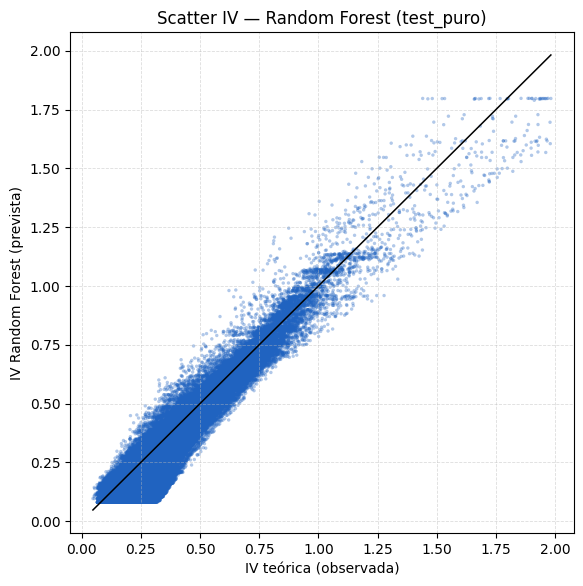

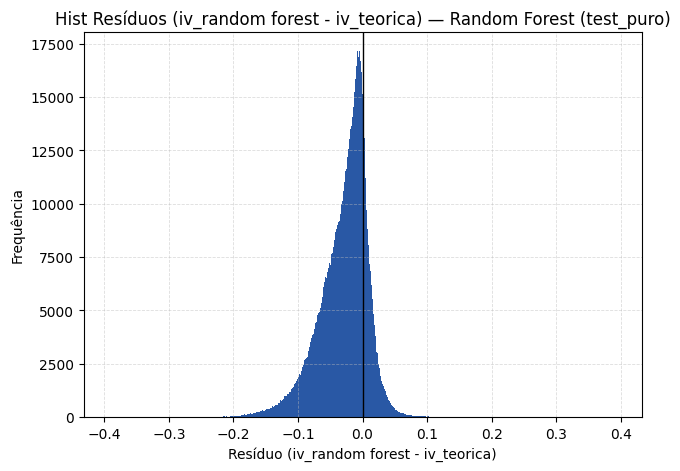

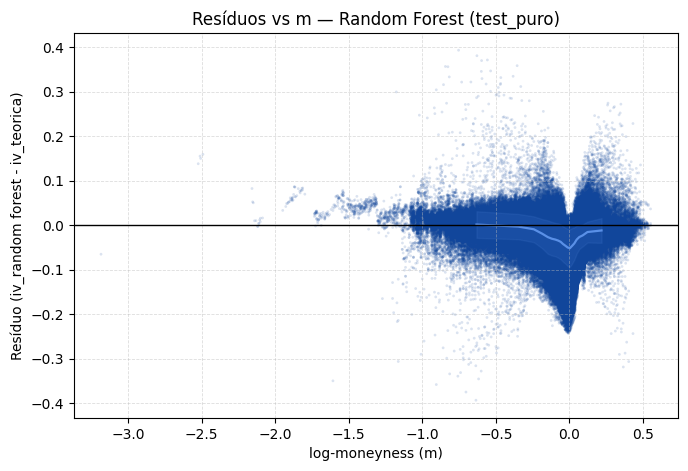

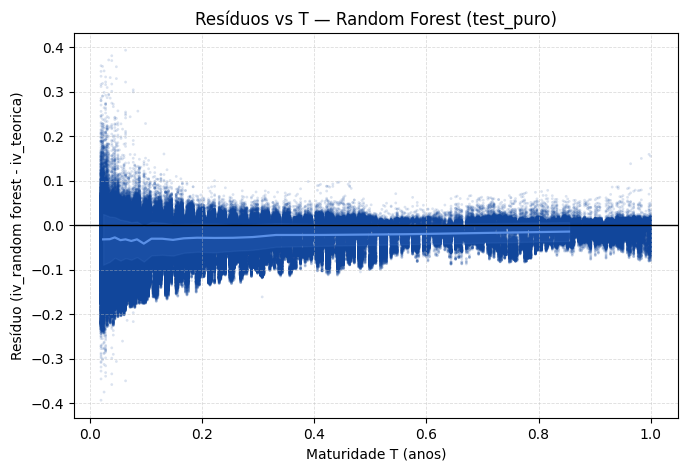

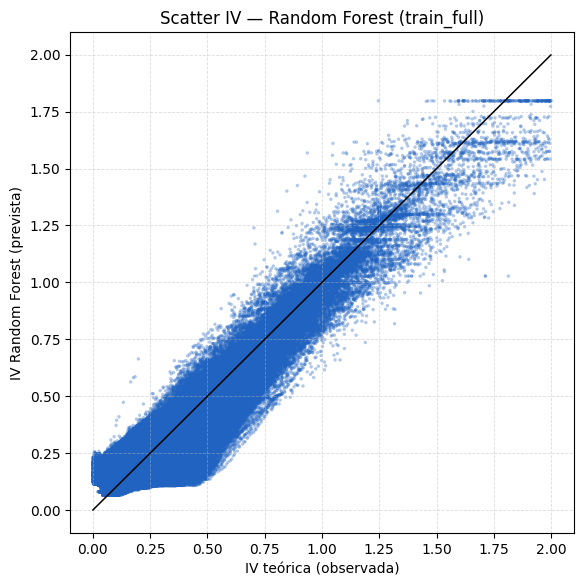

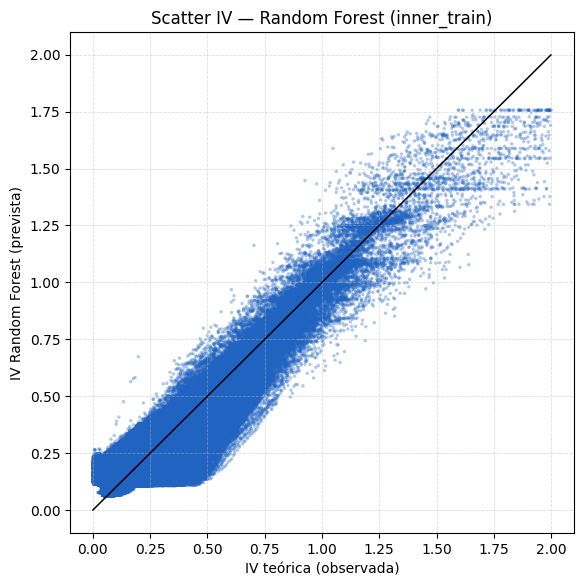

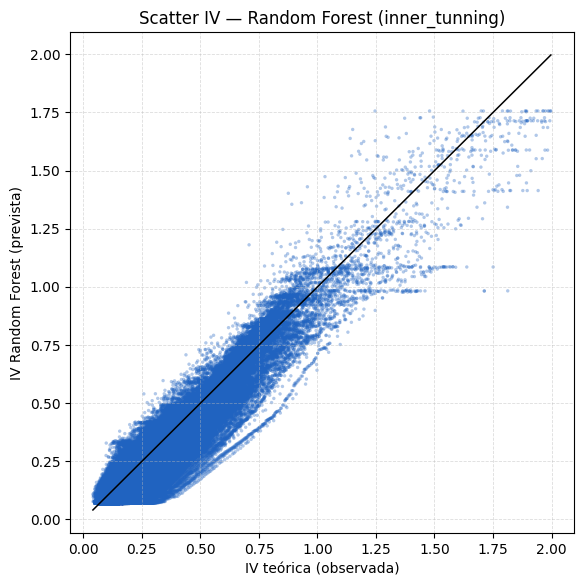

,model,split,analysis,variant,n_obs,RMSE,MAE,MedAE,R2,Bias
0,Random Forest,test_puro,geral,train_full,1292514,0.047577,0.034483,0.024162,0.833238,-0.028708
1,Random Forest,train_full,especifica,train_full,7505238,0.035828,0.022081,0.013643,0.917708,-0.000004
2,Random Forest,inner_train,especifica,inner_training,5970843,0.038392,0.024016,0.015323,0.905137,-0.000005
3,Random Forest,inner_tunning,especifica,inner_training,1534395,0.042438,0.030709,0.022105,0.885323,-0.024939


,model,split,analysis,variant,n_obs,RMSE,MAE,MedAE,R2,Bias
0,Random Forest,test_puro,geral,train_full,1292514,0.047577,0.034483,0.024162,0.833238,-0.028708
1,Random Forest,train_full,especifica,train_full,7505238,0.035828,0.022081,0.013643,0.917708,-0.000004
2,Random Forest,inner_train,especifica,inner_training,5970843,0.038392,0.024016,0.015323,0.905137,-0.000005
3,Random Forest,inner_tunning,especifica,inner_training,1534395,0.042438,0.030709,0.022105,0.885323,-0.024939


In [14]:
# --- chamar a função run_avaliacoes ---
res_rf = run_avaliacoes(
    df_inner_train=df_inner_train_pred,   # contém ivs_modelo
    df_inner_tunning=df_inner_tunning_pred,
    df_train_full=df_train_full_pred,
    df_test_puro=df_test_puro_pred,
    model="Random Forest",
    DIR_TABELAS=DIR_TABELAS,
    DIR_GRAFICOS=DIR_GRAFICOS,
    scatter_mode="all",
    max_points_scatter=250_000,
    dpi=160,
    display_in_notebook=True
)

res_rf["globais_df"].head()

Métricas de Avaliação (pós calibração linear)

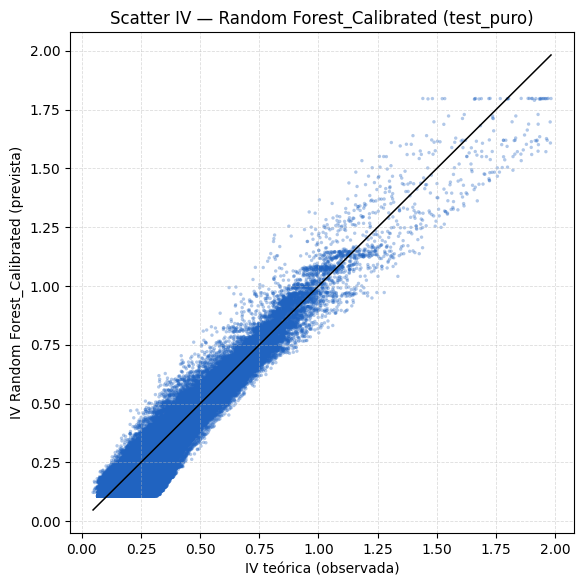

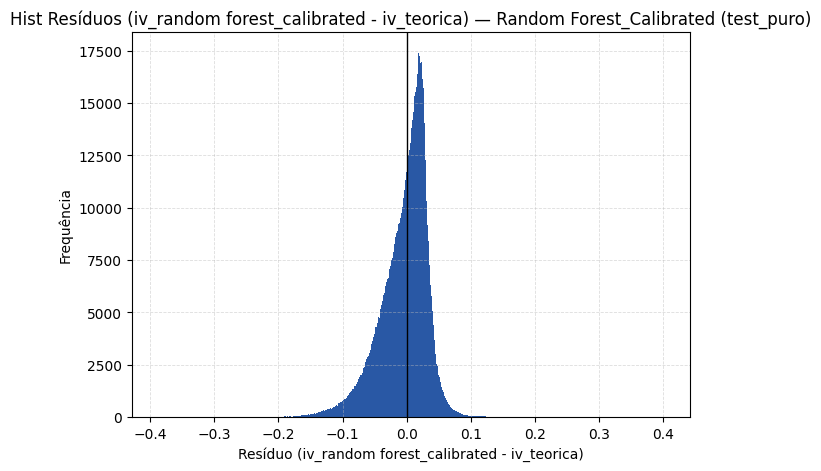

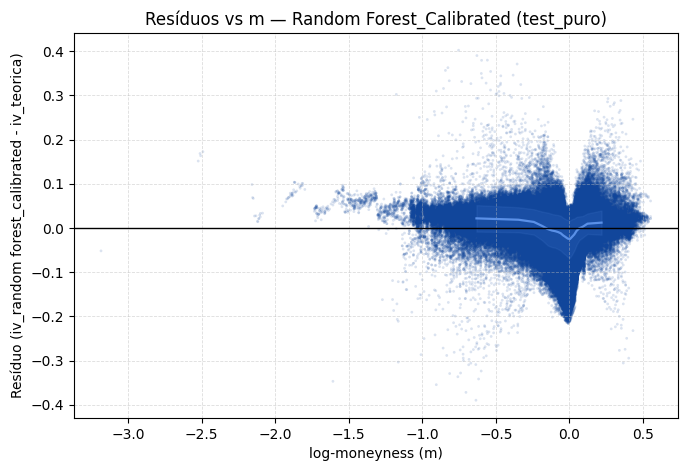

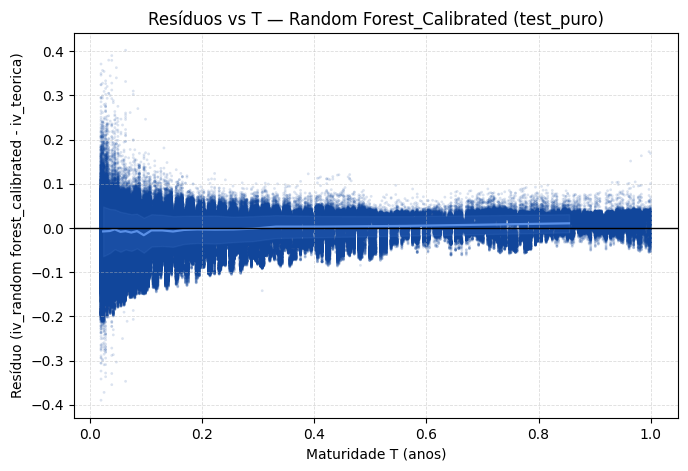

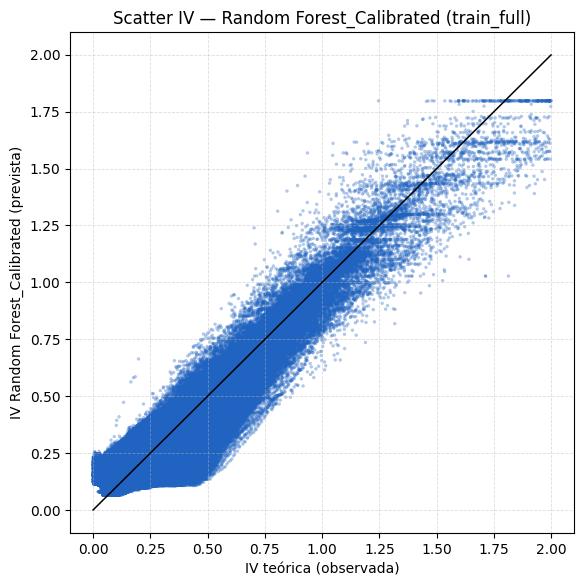

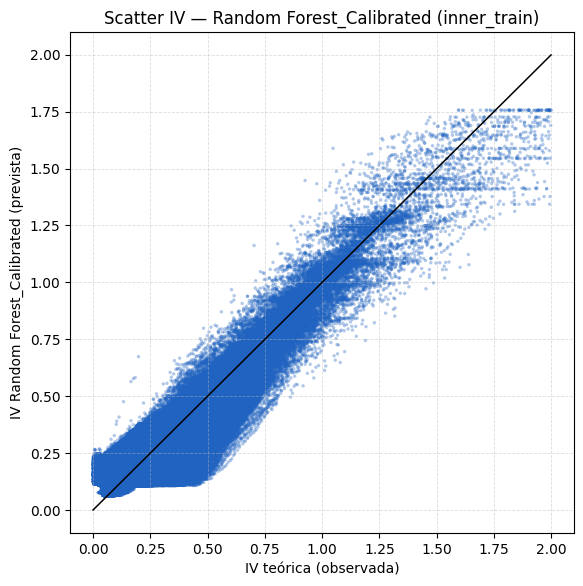

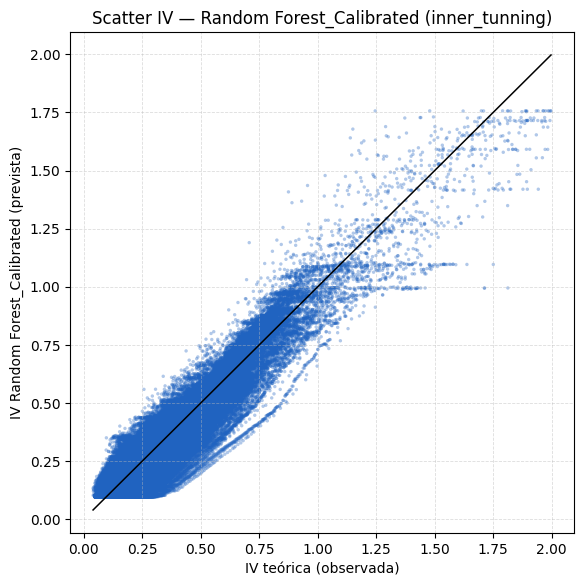

,model,split,analysis,variant,n_obs,RMSE,MAE,MedAE,R2,Bias
0,Random Forest_Calibrated,test_puro,geral,train_full,1292514,0.037514,0.028119,0.022245,0.896319,-3.987206e-03
1,Random Forest_Calibrated,train_full,especifica,train_full,7505238,0.035828,0.022081,0.013643,0.917708,-4.116371e-06
2,Random Forest_Calibrated,inner_train,especifica,inner_training,5970843,0.038392,0.024016,0.015323,0.905137,-4.585490e-06
3,Random Forest_Calibrated,inner_tunning,especifica,inner_training,1534395,0.034283,0.023848,0.017191,0.925159,1.368110e-08


,model,split,analysis,variant,n_obs,RMSE,MAE,MedAE,R2,Bias
0,Random Forest_Calibrated,test_puro,geral,train_full,1292514,0.037514,0.028119,0.022245,0.896319,-3.987206e-03
1,Random Forest_Calibrated,train_full,especifica,train_full,7505238,0.035828,0.022081,0.013643,0.917708,-4.116371e-06
2,Random Forest_Calibrated,inner_train,especifica,inner_training,5970843,0.038392,0.024016,0.015323,0.905137,-4.585490e-06
3,Random Forest_Calibrated,inner_tunning,especifica,inner_training,1534395,0.034283,0.023848,0.017191,0.925159,1.368110e-08


In [18]:
# --- chamar a função run_avaliacoes ---
res_rf = run_avaliacoes(
    df_inner_train=df_inner_train_pred,   # contém ivs_modelo
    df_inner_tunning=df_inner_tunning_pred_cal,
    df_train_full=df_train_full_pred,
    df_test_puro=df_test_puro_pred_cal,
    model="Random Forest_Calibrated",
    DIR_TABELAS=DIR_TABELAS,
    DIR_GRAFICOS=DIR_GRAFICOS,
    scatter_mode="all",
    max_points_scatter=250_000,
    dpi=160,
    display_in_notebook=True
)

res_rf["globais_df"].head()

Visualização Gráfica

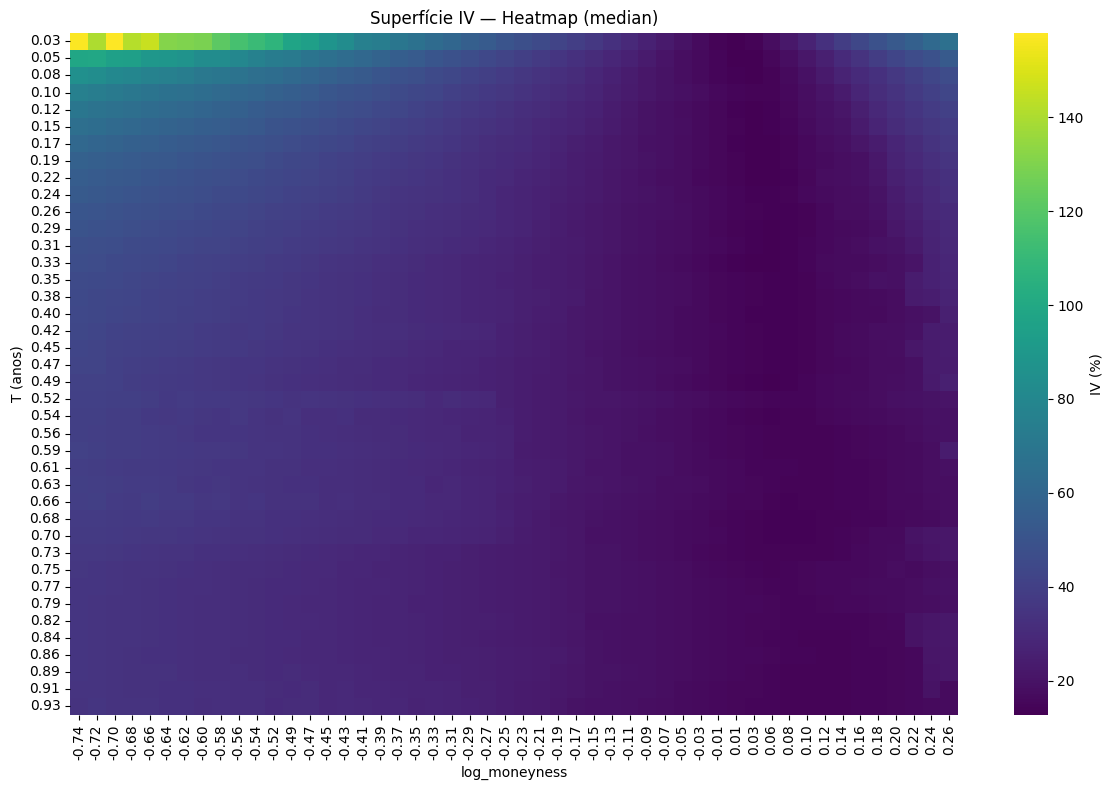

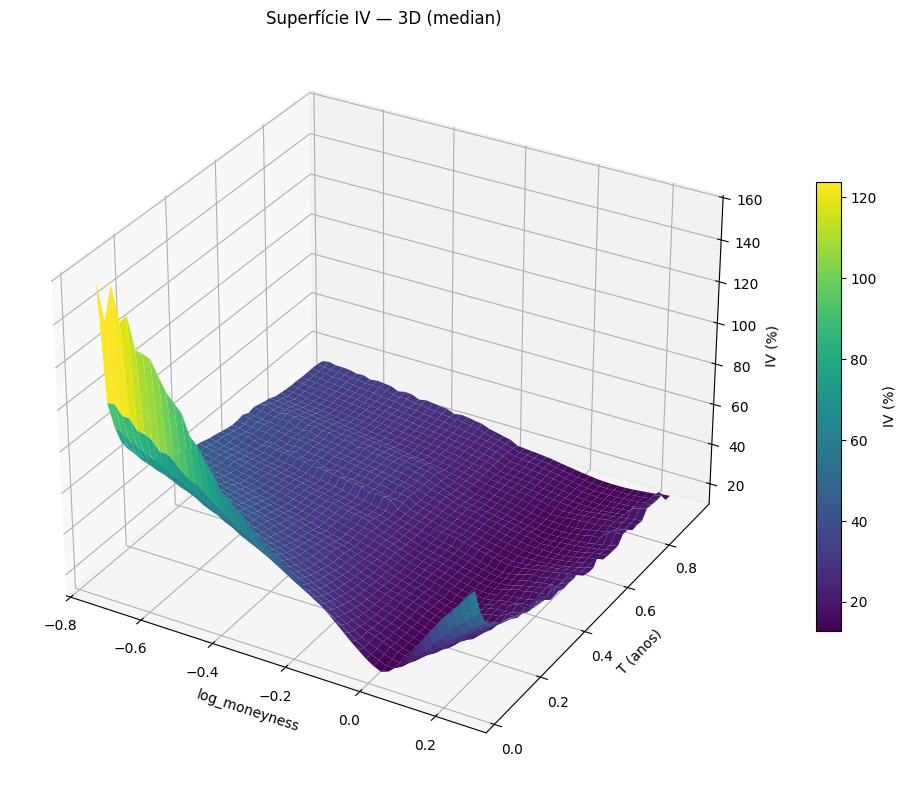

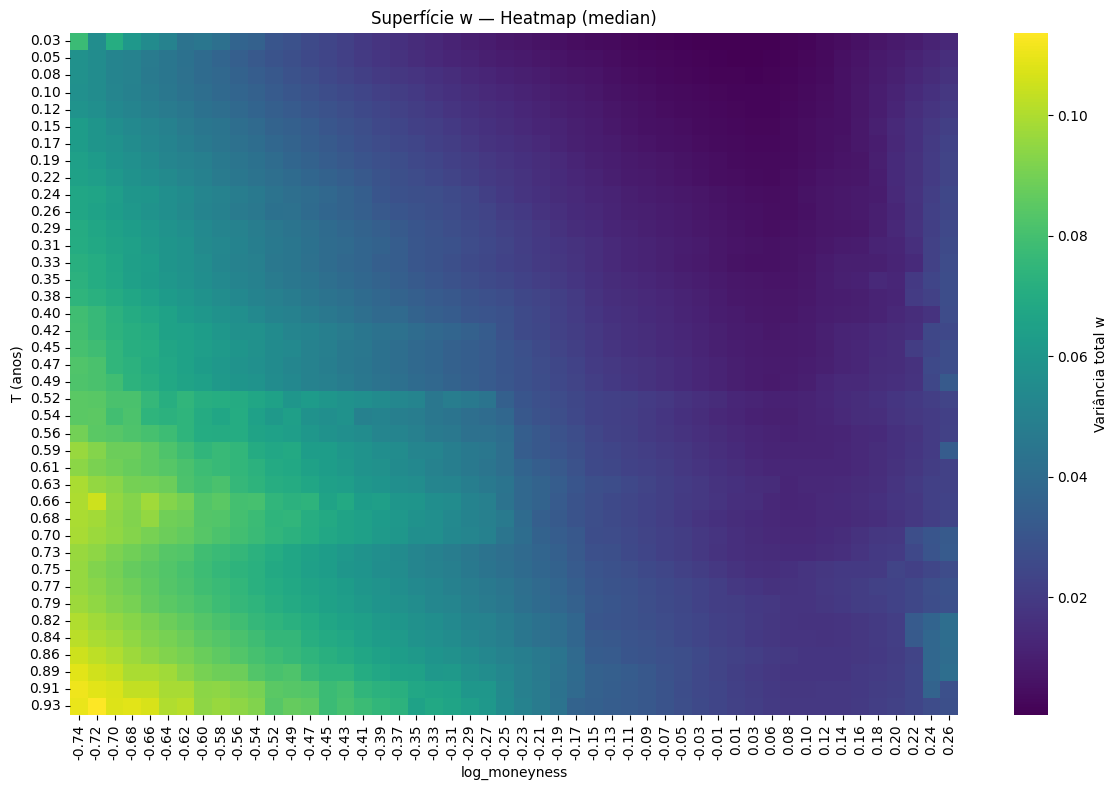

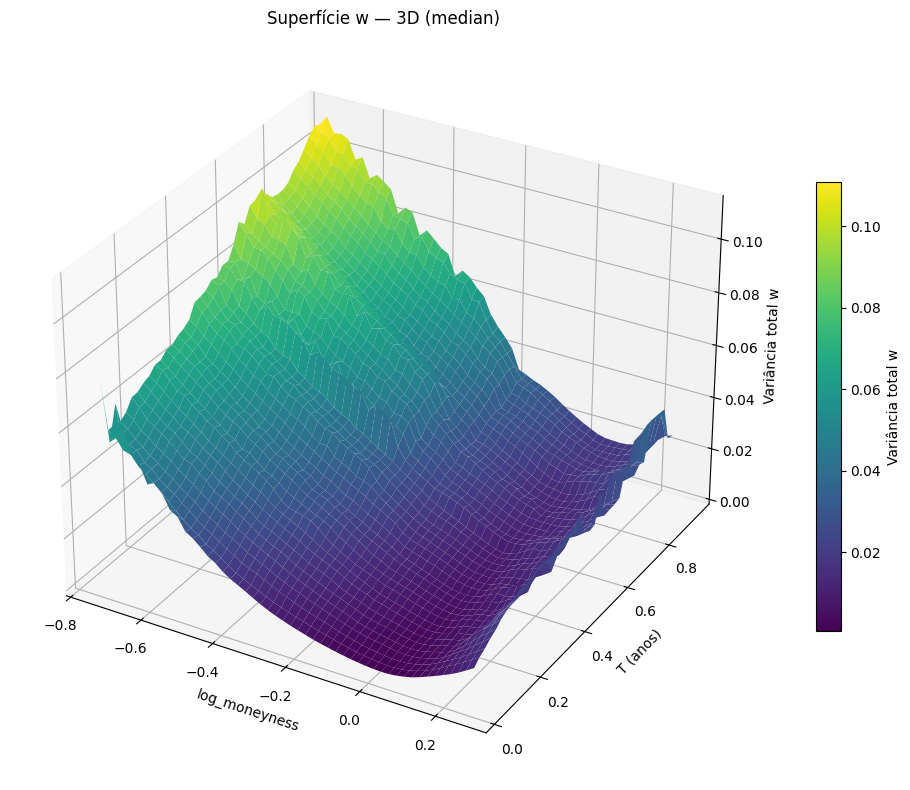

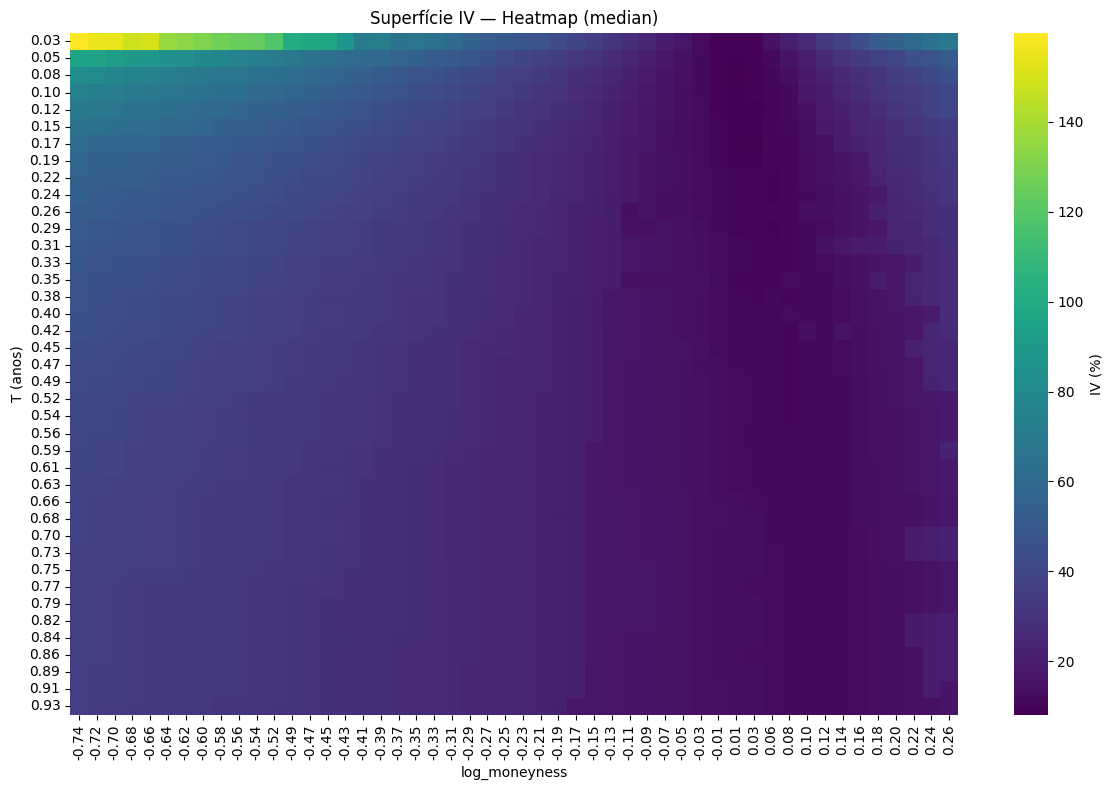

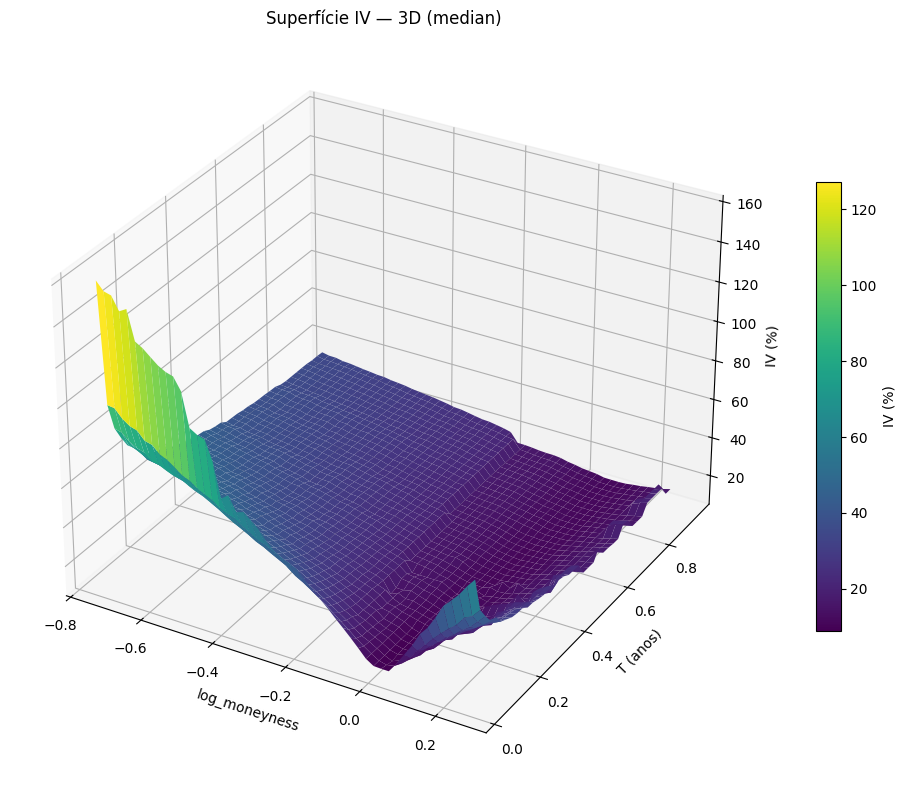

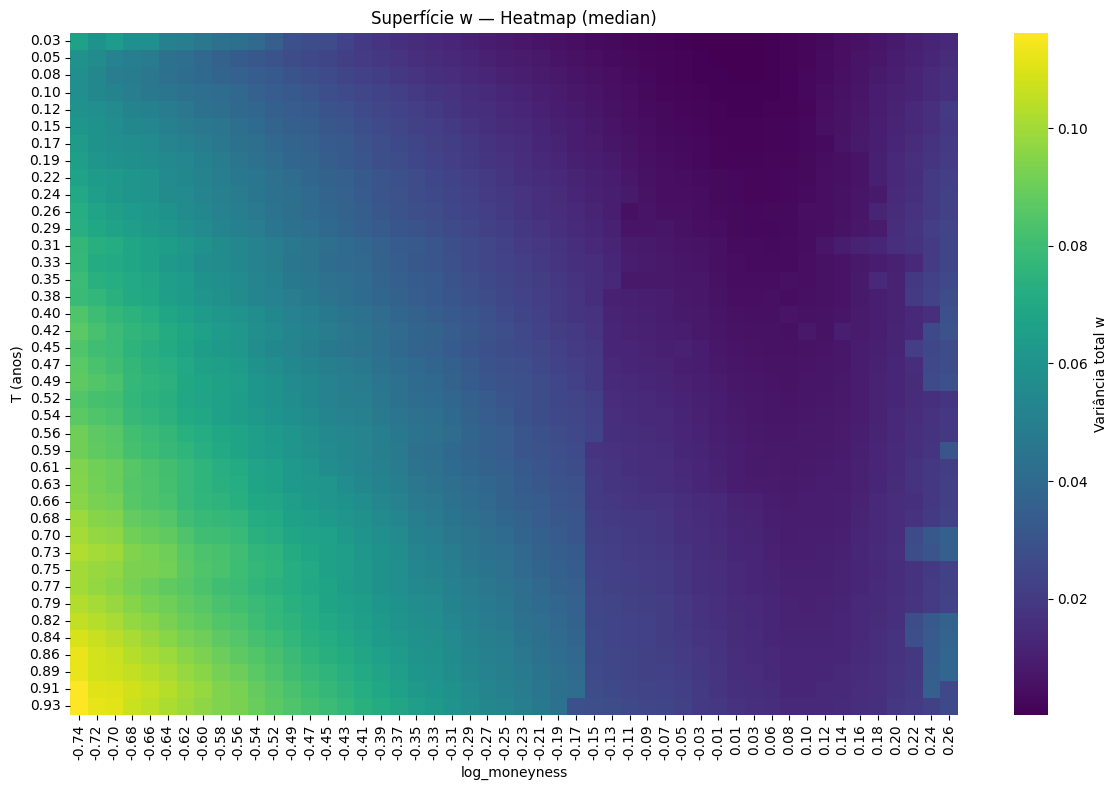

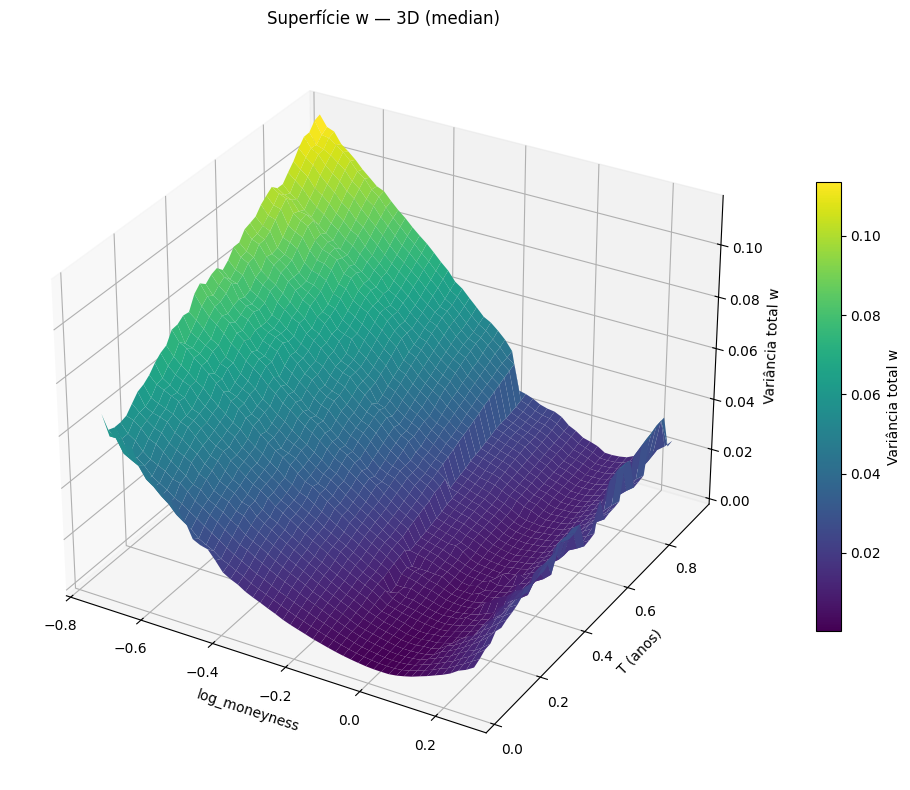

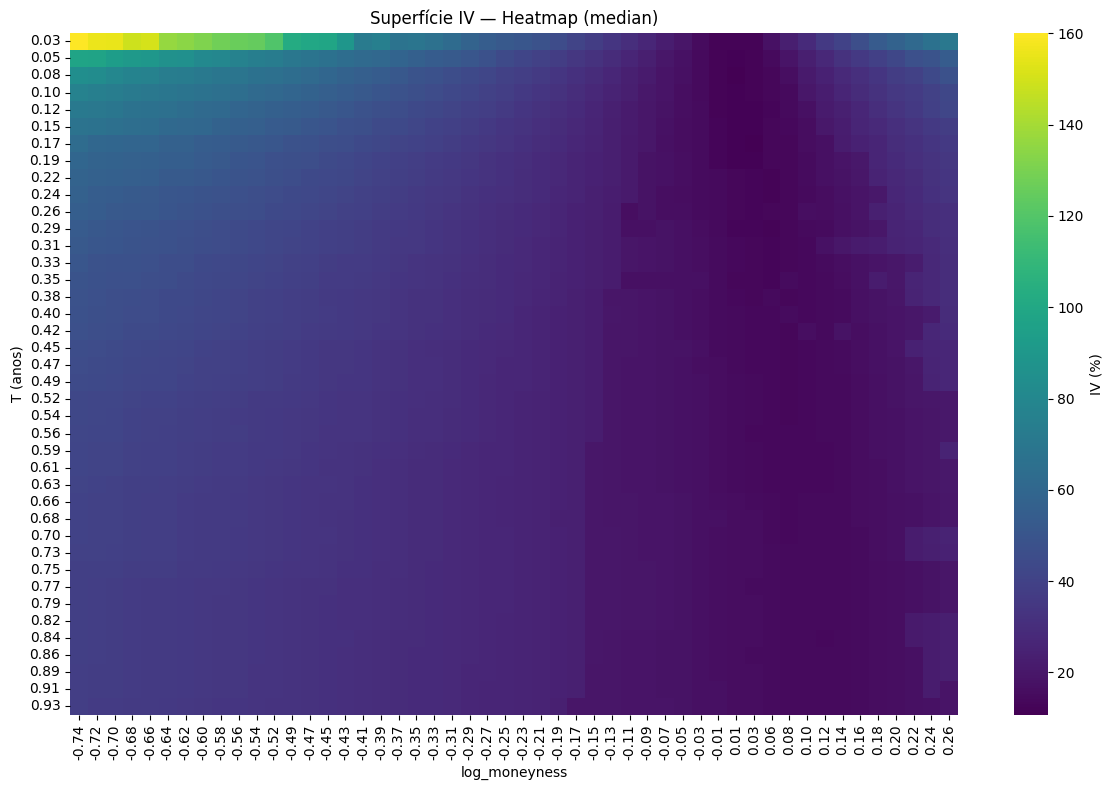

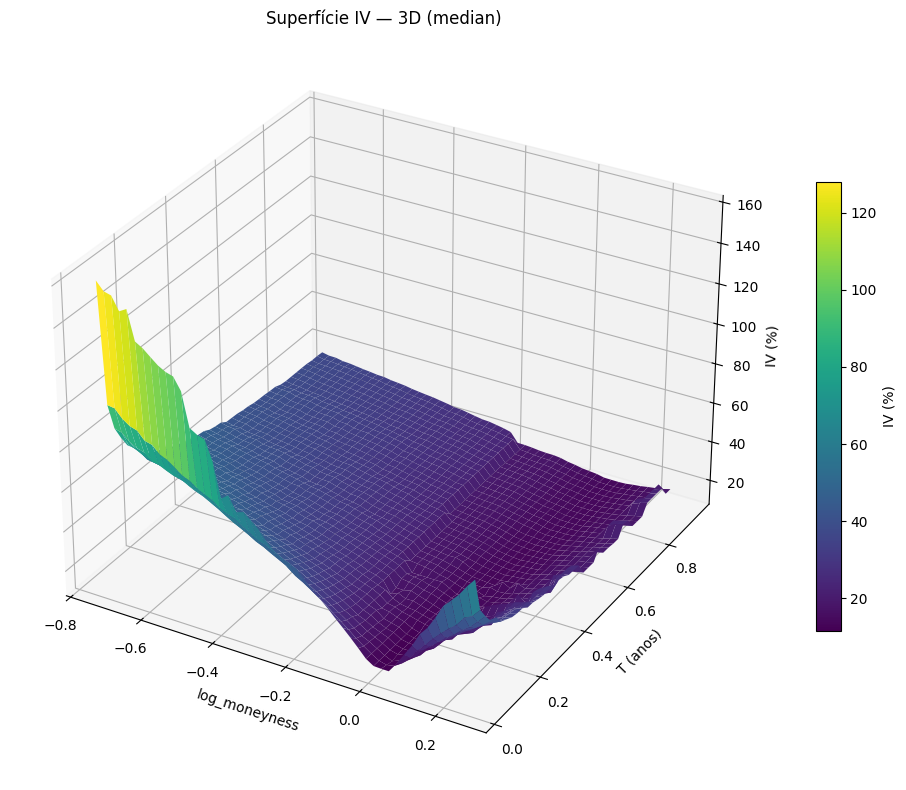

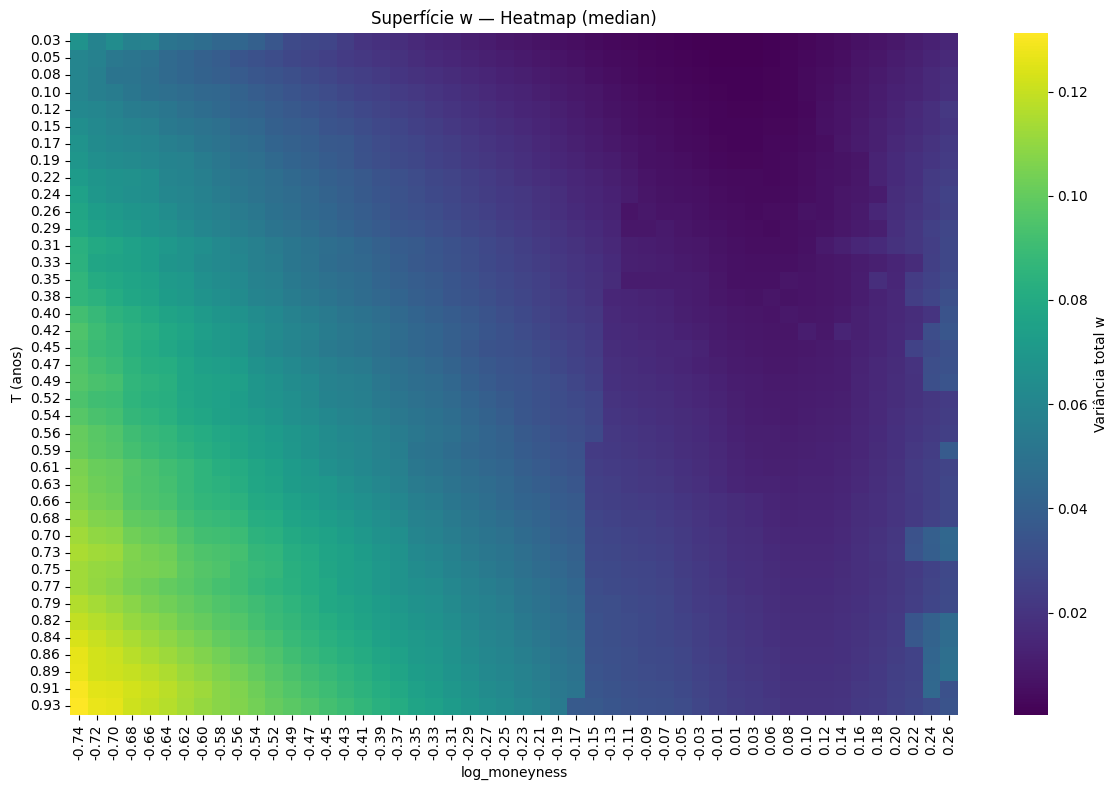

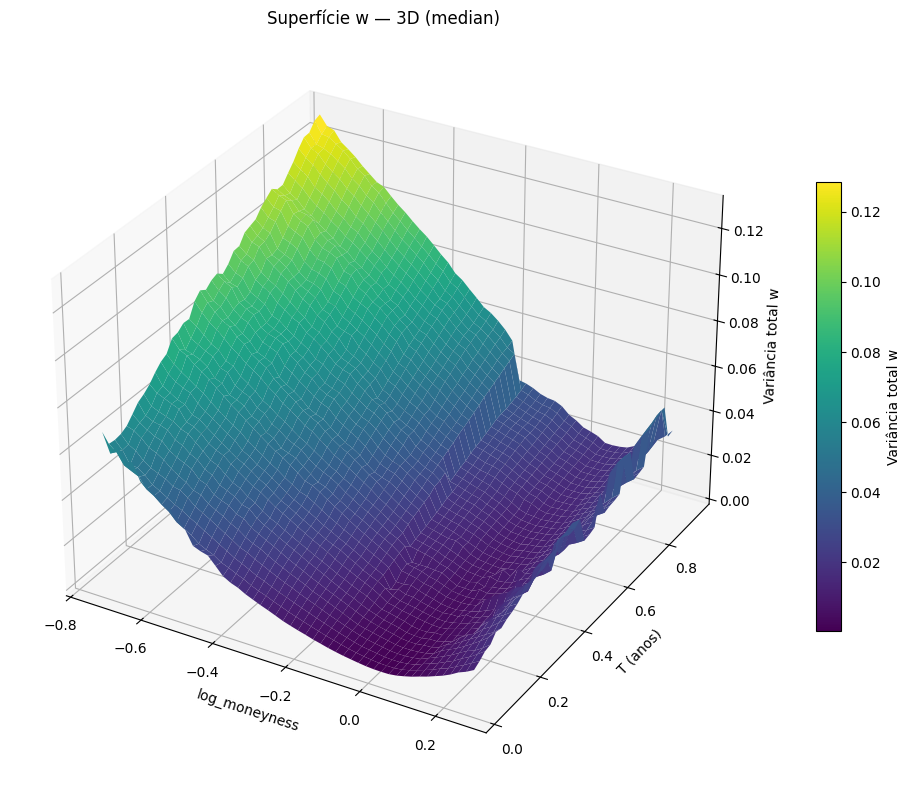

In [20]:
# 1) Superfície teórica
plot_ivs_and_variance_surfaces(
    df_test_puro_pred,
    x_col="log_moneyness", y_col="T", z_col="iv_teorica",
    agg="median",
    nbins_x=50, nbins_y=40,
    save_dir=DIR_GRAFICOS, filename_prefix="Random Forest"
)

# 2) Superfície de volatilidade implícita do modelo (não calibrada)
plot_ivs_and_variance_surfaces(
    df_test_puro_pred,
    x_col="log_moneyness", y_col="T", z_col="ivs_modelo",
    agg="median",
    nbins_x=50, nbins_y=40,
    save_dir=DIR_GRAFICOS, filename_prefix="Random Forest"
)

# 3) Superfície de volatilidade implícita do modelo (calibrada)
plot_ivs_and_variance_surfaces(
    df_test_puro_pred_cal,
    x_col="log_moneyness", y_col="T", z_col="ivs_modelo",
    agg="median",
    nbins_x=50, nbins_y=40,
    save_dir=DIR_GRAFICOS, filename_prefix="Random Forest"
)